In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import mutual_info_score
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import squareform
import os

In [2]:

# Data import:
#os.chdir('C:/Users/p528552/OneDrive - South African Reserve Bank/Documents/1. MEng - Data Science/1. Project_2025/Data/factor_timing/legacy/data_input')
os.chdir('C:/Users/ccwis/OneDrive/Documents/1. MEng - Data Science/Project/factor_timing/legacy/data_input')

data = pd.read_csv("featureset.csv", parse_dates=['Date'],na_values=['NA'])
data = data.set_index('Date')


# --- Drop features with more than 30% missing values ---
threshold = 0.30
missing_ratio = data.isnull().mean()
cols_to_drop = missing_ratio[missing_ratio > threshold].index
data = data.drop(columns=cols_to_drop)


feature_names = data.columns[:-1]

# --- Forward-fill remaining missing values ---
data = data.ffill()
data = data.dropna()

X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values



#X = pd.DataFrame(X, columns=feature_names)
print(data)


            VolTermStructPC1  VolTermStructPC2  VolTermStructPC1_QS  \
Date                                                                  
2012-03-26         36.869615        -10.228845                 0.01   
2012-04-02         38.620657         -9.588153                 0.07   
2012-04-09         43.657669         -9.057927                 0.33   
2012-04-16         45.488405         -9.545301                 0.47   
2012-04-23         44.514050         -9.720469                 0.37   
...                      ...               ...                  ...   
2025-03-03         44.421245         -5.261720                 0.98   
2025-03-10         51.117954         -3.610349                 0.99   
2025-03-17         42.305038         -6.657027                 0.92   
2025-03-24         38.142130         -7.595933                 0.70   
2025-03-31         44.285942         -6.064842                 0.96   

            VolTermStructPC2_QS  VolSpread6M  VIX.Index  VIX3M.Index  \
Date

In [3]:
#data.to_csv("data.csv",index=True)

In [4]:


# ======================================================
# 1. Normalized Mutual Information
# ======================================================

def normalized_mi(x, y, n_bins=20):
    # Use separate discretizers to avoid identical binning
    kb_x = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')
    kb_y = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile')

    x_binned = kb_x.fit_transform(x.reshape(-1, 1))
    y_binned = kb_y.fit_transform(y.reshape(-1, 1))

    mi = mutual_info_score(x_binned[:, 0], y_binned[:, 0])
    h_x = mutual_info_score(x_binned[:, 0], x_binned[:, 0])
    h_y = mutual_info_score(y_binned[:, 0], y_binned[:, 0])

    denom = max(h_x, h_y)
    return 0 if denom == 0 else mi / denom


# ======================================================
# 2. Build the MI Distance Matrix (1 - NMI)
# ======================================================

def mi_distance_matrix(X, n_bins=20):
    n = X.shape[1]
    dist_matrix = np.zeros((n, n))
    cols = X.columns.to_list()

    print(f"Computing MI distance matrix for {n} features...")

    for i in tqdm(range(n)):
        for j in range(i + 1, n):
            try:
                nmi = normalized_mi(X.iloc[:, i].values, X.iloc[:, j].values, n_bins=n_bins)
                dist = 1 - nmi
            except Exception:
                dist = 1  # default max distance on failure
            dist_matrix[i, j] = dist_matrix[j, i] = dist

    np.fill_diagonal(dist_matrix, 0)
    return pd.DataFrame(dist_matrix, index=cols, columns=cols)



# ======================================================
# 3. Cluster Features
# ======================================================
def cluster_features(D, method='ward', threshold=None, n_clusters=None):
    Z = linkage(D, method=method)

    if n_clusters is not None:
        cluster_labels = fcluster(Z, t=n_clusters, criterion='maxclust')
        print(f"Formed {n_clusters} clusters using 'maxclust'.")
    elif threshold is not None:
        cluster_labels = fcluster(Z, t=threshold, criterion='distance')
        print(f"Formed {len(np.unique(cluster_labels))} clusters using distance threshold={threshold}.")
    else:
        raise ValueError("Provide either n_clusters or a distance threshold.")

    return pd.Series(cluster_labels, index=D.index), Z


# ======================================================
# 4. Representative Selection
# ======================================================

def get_cluster_representatives(D, cluster_labels):

    representatives = []

    for c in sorted(cluster_labels.unique()):
        feats = cluster_labels[cluster_labels == c].index
        sub_D = D.loc[feats, feats]

        # Compute distances
        mean_dist = sub_D.mean(axis=1)
        min_dist = sub_D.min(axis=1)
        max_dist = sub_D.max(axis=1)

        # Representative = feature with lowest mean distance
        rep_feature = mean_dist.idxmin()

        representatives.append({
            "Cluster": c,
            "Representative": rep_feature,
            "Mean_Distance": mean_dist[rep_feature],
            "Max_Distance": max_dist[rep_feature],
            "Cluster_Size": len(feats)
        })

    return pd.DataFrame(representatives).sort_values("Cluster")




In [5]:
# Express X is a DataFrame
X = pd.DataFrame(X, columns=feature_names)


In [6]:
# ======================================================
# Application - calcuate the distance matrix
# ======================================================

D = mi_distance_matrix(X)

Computing MI distance matrix for 343 features...


  0%|          | 0/343 [00:00<?, ?it/s]c:\Users\ccwis\anaconda3\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\ccwis\anaconda3\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\ccwis\anaconda3\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavio

In [7]:
# ======================================================
# Application - arbitrary number of clusters
# ======================================================

# Use no. of clusters:
#cluster_labels, Z = cluster_features(D, n_clusters=38)

# Use distance threshold:
cluster_labels, Z = cluster_features(D, threshold=2)

C:\Users\ccwis\AppData\Local\Temp\ipykernel_23476\2246026845.py:50: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  Z = linkage(D, method=method)


Formed 32 clusters using distance threshold=2.


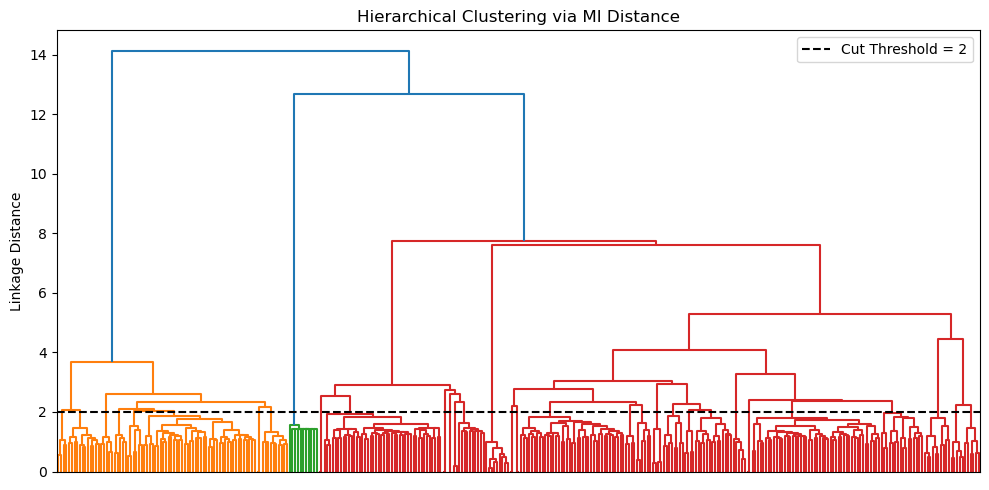

In [8]:
"""      
# Plot dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z, labels=D.index, leaf_rotation=90)
plt.title("Hierarchical Clustering via MI Distance")
plt.tight_layout()
plt.show()
"""
# Plot dendrogram
plt.figure(figsize=(10, 5))
#plt.text(2.05, 50, "Cut Threshold = 2", color='red')
dendrogram(
    Z,
    no_labels=True
)

# Add horizontal cut line at distance = 2
plt.axhline(y=2, color='black', linestyle='--', linewidth=1.5,label='Cut Threshold = 2')
plt.title("Hierarchical Clustering via MI Distance")
plt.ylabel("Linkage Distance")
plt.legend()
plt.tight_layout()
plt.show()


In [9]:
def choose_optimal_clusters(D, min_k=5, max_k=100):
    D_condensed = squareform(D.values)  # required for hierarchical clustering
    scores = {}

    for k in range(min_k, max_k + 1):
        labels = fcluster(Z, t=k, criterion='maxclust')
        score = silhouette_score(D, labels, metric='precomputed')
        scores[k] = score
    
    return scores

scores = choose_optimal_clusters(D)

best_k = max(scores, key=scores.get)
print("Optimal number of clusters =", best_k)



Optimal number of clusters = 100


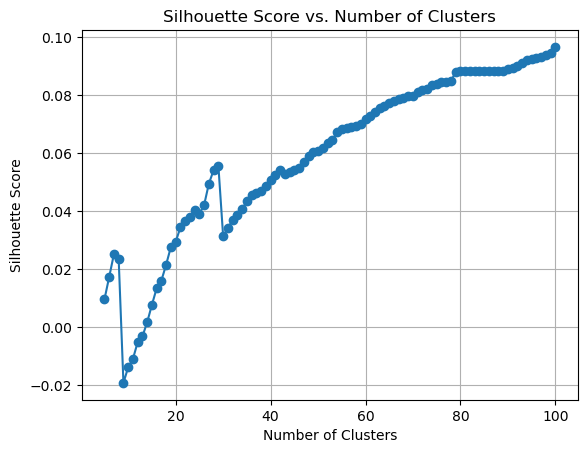

In [10]:
plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.title("Silhouette Score vs. Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

In [11]:
# ======================================================
# Application - get cluster representatives
# ======================================================

representatives = get_cluster_representatives(D, cluster_labels)

In [12]:
display(representatives.style.background_gradient(cmap="viridis", subset=["Mean_Distance","Max_Distance"])
                             .bar(subset=["Cluster_Size"], color="darkblue"))


,Cluster,Representative,Mean_Distance,Max_Distance,Cluster_Size
0,1,BCMPEBLS.Index,0.319443,0.507076,4
1,2,GlobalPropertyVol12,0.576340,0.675355,12
2,3,MXWD_Fundamental_PC1,0.414122,0.565161,5
3,4,SA_CDS_Slope,0.446126,0.671824,5
4,5,SA_RB_Curvature,0.497313,0.732496,6
5,6,JALSH_Fundamental_PC1,0.693928,0.755322,42
6,7,RandPPP_Factor_Inst_TS_ST,0.000000,0.000000,2
7,8,MichgnConcIndx,0.555859,0.638860,10
8,9,PPP.ZA.Index_QS,0.909091,1.000000,11
9,10,GLD_FracDiff,0.000000,0.000000,2


In [13]:
# View cluster representatives
clusters= representatives.to_csv('appendix_representatives.csv',index=True)


In [14]:
def compute_mean_distances_per_feature(D, cluster_labels):
    """
    For each feature, compute the mean MI-distance to others in the same cluster.
    Returns a DataFrame with Feature, Cluster, Mean_Distance.
    """
    records = []

    for c in sorted(cluster_labels.unique()):
        feats = cluster_labels[cluster_labels == c].index
        sub_D = D.loc[feats, feats]    # submatrix of distances for this cluster

        # mean distance for each feature
        mean_dist = sub_D.mean(axis=1)

        for f in feats:
            records.append({
                "Feature": f,
                "Cluster": c,
                "Mean_Distance": mean_dist[f]
            })

    return pd.DataFrame(records)



In [15]:
# Compute mean distance for every feature
feature_distances = compute_mean_distances_per_feature(D, cluster_labels)

# Sort for readability
feature_distances = feature_distances.sort_values(["Cluster", "Mean_Distance"]).reset_index(drop=True)

# Save to CSV
#feature_distances.to_csv("feature_clusters.csv", index=False)

print("Saved feature_clusters.csv")
print(feature_distances.head())


Saved feature_clusters.csv
               Feature  Cluster  Mean_Distance
0       BCMPEBLS.Index        1       0.319443
1            SACWC_YoY        1       0.323505
2       LEI.TOTL.Index        1       0.361497
3         OEZAKLAF_YoY        1       0.394444
4  GlobalPropertyVol12        2       0.576340
